<a href="https://colab.research.google.com/github/TanSha15/Analysis-Visualization-IPL/blob/main/Analysis_Visualization_IPL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [12]:
df = pd.read_csv("IPL.csv")
df.head()

,match_id,date,venue,team1,team2,stage,toss_winner,toss_decision,first_ings_score,first_ings_wkts,second_ings_score,second_ings_wkts,match_winner,won_by,margin,player_of_the_match,top_scorer,highscore,best_bowling,best_bowling_figure
0,1,"March 26,2022","Wankhede Stadium, Mumbai",Chennai,Kolkata,Group,Kolkata,Field,131,5,133,4,Kolkata,Wickets,6,Umesh Yadav,MS Dhoni,50,Dwayne Bravo,3--20
1,2,"March 27,2022","Brabourne Stadium, Mumbai",Delhi,Mumbai,Group,Delhi,Field,177,5,179,6,Delhi,Wickets,4,Kuldeep Yadav,Ishan Kishan,81,Kuldeep Yadav,3--18
2,3,"March 27,2022","Dr DY Patil Sports Academy, Mumbai",Banglore,Punjab,Group,Punjab,Field,205,2,208,5,Punjab,Wickets,5,Odean Smith,Faf du Plessis,88,Mohammed Siraj,2--59
3,4,"March 28,2022","Wankhede Stadium, Mumbai",Gujarat,Lucknow,Group,Gujarat,Field,158,6,161,5,Gujarat,Wickets,5,Mohammed Shami,Deepak Hooda,55,Mohammed Shami,3--25
4,5,"March 29,2022","Maharashtra Cricket Association Stadium,Pune",Hyderabad,Rajasthan,Group,Hyderabad,Field,210,6,149,7,Rajasthan,Runs,61,Sanju Samson,Aiden Markram,57,Yuzvendra Chahal,3--22


In [18]:
print(f"No. of rows: {df.shape[0]}")
print(f"No. of columns: {df.shape[1]}")

No. of rows: 74
No. of columns: 20


In [14]:
df.info() #74 null values hence

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74 entries, 0 to 73
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   match_id             74 non-null     int64 
 1   date                 74 non-null     object
 2   venue                74 non-null     object
 3   team1                74 non-null     object
 4   team2                74 non-null     object
 5   stage                74 non-null     object
 6   toss_winner          74 non-null     object
 7   toss_decision        74 non-null     object
 8   first_ings_score     74 non-null     int64 
 9   first_ings_wkts      74 non-null     int64 
 10  second_ings_score    74 non-null     int64 
 11  second_ings_wkts     74 non-null     int64 
 12  match_winner         74 non-null     object
 13  won_by               74 non-null     object
 14  margin               74 non-null     int64 
 15  player_of_the_match  74 non-null     object
 16  top_scorer

In [21]:
print(f"No. of Null values: \n{df.isnull().sum()}")

No. of Null values: 
match_id               0
date                   0
venue                  0
team1                  0
team2                  0
stage                  0
toss_winner            0
toss_decision          0
first_ings_score       0
first_ings_wkts        0
second_ings_score      0
second_ings_wkts       0
match_winner           0
won_by                 0
margin                 0
player_of_the_match    0
top_scorer             0
highscore              0
best_bowling           0
best_bowling_figure    0
dtype: int64


In [30]:
#Teams that won the most matches
match_wins = df['match_winner'].value_counts()
print(f"Team that won the most matches: \n{match_wins}")

Team that won the most matches: 
match_winner
Gujarat      12
Rajasthan    10
Banglore      9
Lucknow       9
Punjab        7
Delhi         7
Kolkata       6
Hyderabad     6
Chennai       4
Mumbai        4
Name: count, dtype: int64


Text(0, 0.5, 'Teams')

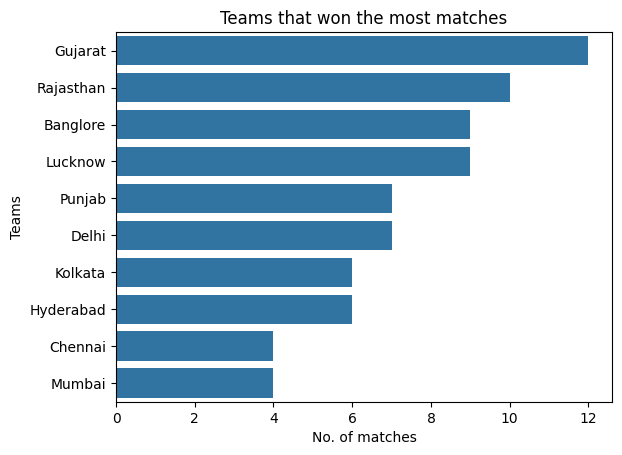

In [33]:
#Plotting bar graph
sns.barplot(y=match_wins.index,x=match_wins.values)
plt.title("Teams that won the most matches")
plt.xlabel("No. of matches")
plt.ylabel("Teams")

Text(0, 0.5, 'No. of times')

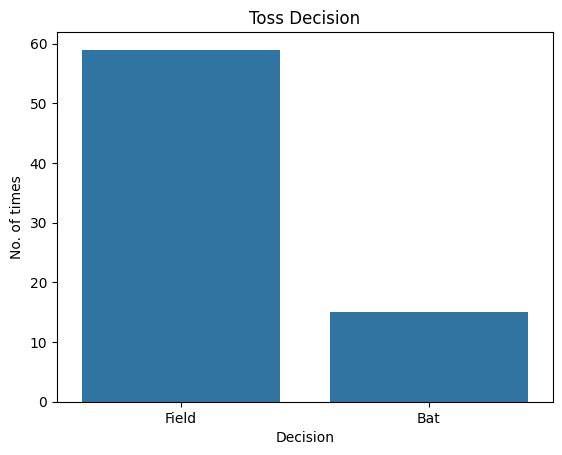

In [35]:
sns.countplot(x = df['toss_decision'])
plt.title("Toss Decision")
plt.xlabel("Decision")
plt.ylabel("No. of times")

In [38]:
#toss winner vs match winner
count = df[df['toss_winner'] == df['match_winner']]['match_id'].count()
percentage = (count*100)/df.shape[0]
percentage.round(2)

np.float64(48.65)

Text(0, 0.5, 'No. of times')

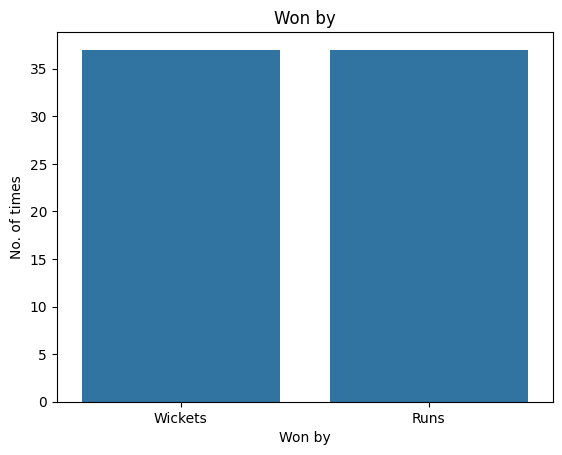

In [40]:
#won by wickets and run
sns.countplot(x = df['won_by'])
plt.title("Won by")
plt.xlabel("Won by")
plt.ylabel("No. of times")

Text(0, 0.5, 'Players')

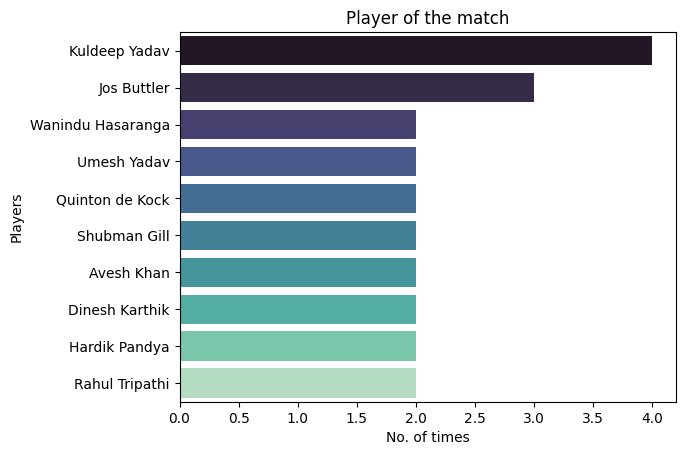

In [54]:

#player of the match
potm = df['player_of_the_match'].value_counts().head(10)
sns.barplot(y=potm.index,x=potm.values,palette='mako')
plt.title("Player of the match")
plt.xlabel("No. of times")
plt.ylabel("Players")

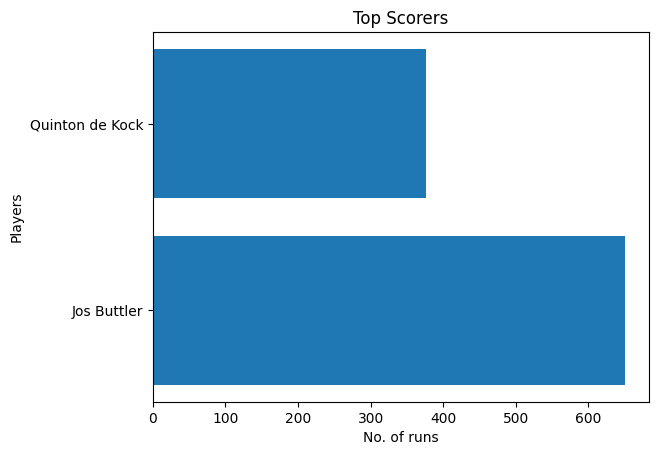

In [63]:
# Top scorers
topScorers = df.groupby('top_scorer')['highscore'].sum().sort_values(ascending=False).head(2)

plt.barh(y=topScorers.index, width=topScorers.values)
plt.title("Top Scorers")
plt.xlabel("No. of runs")
plt.ylabel("Players")
plt.show()

<Axes: ylabel='best_bowling'>

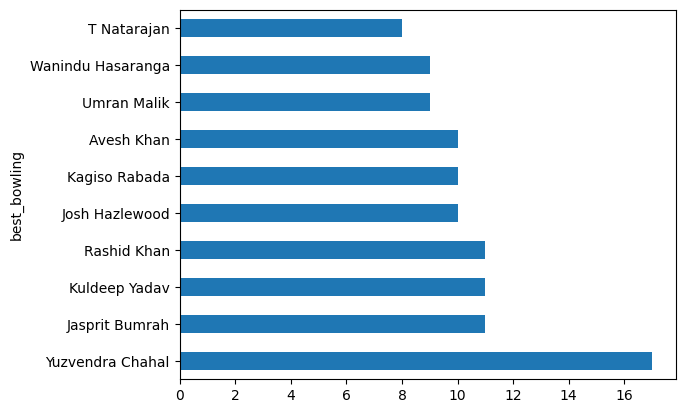

In [64]:
#HIGHEST WICKETS
df['highest_wickets'] = df['best_bowling_figure'].apply(lambda x :x.split('--')[0])
df['highest_wickets'] = df['highest_wickets'].astype(int)
top_bowlers = df.groupby('best_bowling')['highest_wickets'].sum().sort_values(ascending=False).head(10)
top_bowlers.plot(kind = 'barh')

Text(0, 0.5, 'Venue')

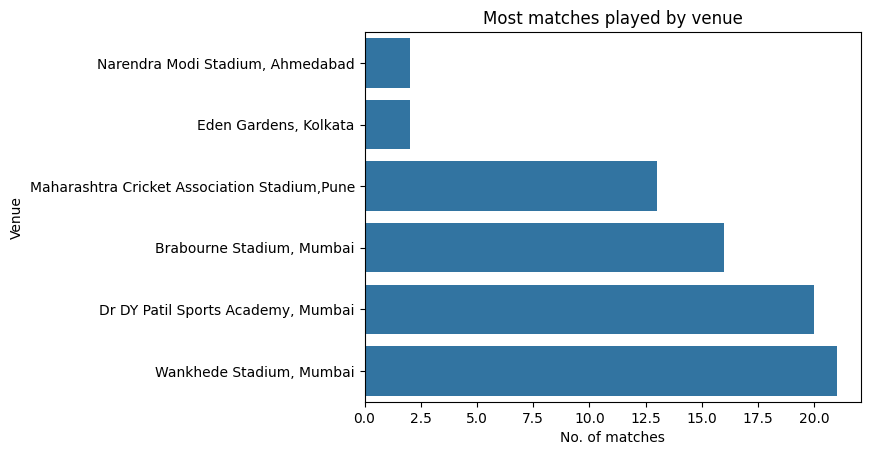

In [71]:
#most match played by venue
venueCount = df['venue'].value_counts().sort_values(ascending=True)
sns.barplot(y=venueCount.index,x=venueCount.values)
plt.title("Most matches played by venue")
plt.xlabel("No. of matches")
plt.ylabel("Venue")